<a href="https://colab.research.google.com/github/CLukashanets-MC/DATA201-assignments/blob/main/DATA201_week08_hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# load libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# load dataset
raw = load_data("Hitters")

# remove na values
raw.shape
print(raw.isna().sum())
data = raw.dropna(subset=['Salary']).copy()

X = data.drop(columns='Salary')
y = data['Salary']

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0)

AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
Salary       59
NewLeague     0
dtype: int64


In [ ]:
def make_preprocessor():
  return ColumnTransformer(
      transformers=[
          ('num', StandardScaler(), numeric_cols),
          ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
      ])

In [ ]:
alpha_values = [0.1, 10, 100]
evaluation = []

for a in alpha_values:
  lasso = Pipeline([
      ('preprocess', make_preprocessor()),
      ('model', Lasso(max_iter=20000).set_params(alpha=a))
  ])

  lasso.fit(X_train, y_train)
  coefs = lasso.named_steps['model'].coef_
  # for Q1 of part 3:
  print(pd.DataFrame(X_train.columns, coefs))

  evaluation.append({
      'alpha': a,
      'training RMSE': np.sqrt(mean_squared_error(y_train, lasso.predict(X_train))),
      'test RMSE': np.sqrt(mean_squared_error(y_test, lasso.predict(X_test))),
      'non-zero coefs': int(np.sum(np.abs(coefs) > 0))
  })

evaluation = pd.DataFrame(evaluation)
evaluation

                     0
-268.516120      AtBat
 313.616475       Hits
 93.905229       HmRun
-40.396617        Runs
-67.252689         RBI
 150.889674      Walks
 23.363661       Years
-302.772800     CAtBat
 187.020482      CHits
-38.689222      CHmRun
 312.532234      CRuns
 191.943928       CRBI
-216.394200     CWalks
 56.165934      League
 66.657335    Division
-38.614242     PutOuts
 31.867806     Assists
-114.361438     Errors
 4.079040    NewLeague
                     0
-0.000000        AtBat
 95.339797        Hits
 11.805232       HmRun
 0.000000         Runs
 0.000000          RBI
 60.877323       Walks
 0.000000        Years
 0.000000       CAtBat
 120.736750      CHits
 0.000000       CHmRun
 11.741383       CRuns
 43.395507        CRBI
-0.000000       CWalks
 38.145780      League
 0.000000     Division
-15.089551     PutOuts
 0.000000      Assists
-85.373515      Errors
 0.000000    NewLeague
                    0
 0.000000       AtBat
 59.360355       Hits
 0.000000     

,alpha,training RMSE,test RMSE,non-zero coefs
0,0.1,294.494460,358.986729,19
1,10.0,311.731209,382.863119,9
2,100.0,347.987473,444.114581,4


Question 1: As α increases, what happens to the number of retained predictors?
The number of retained coefficients decreases.

Question 2: Does a smaller number of predictors always lead to a lower test RMSE?
No, per the table above.

Part 2:

<function matplotlib.pyplot.show(close=None, block=None)>

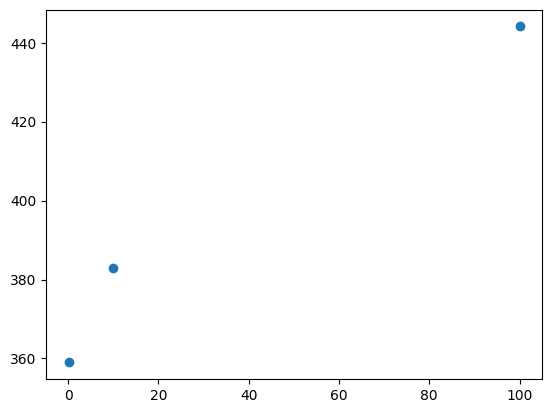

In [ ]:
plt.scatter(evaluation['alpha'], evaluation['test RMSE'], marker = 'o')
plt.show

Question 1: Which α produces the lowest test RMSE among the three values?
alpha = 0.1.

Question 2: Which α appears to cause the most underfitting? Explain using bias.

alpha=100 produces the highest test RMSE of 444.115. This indicates that the model is underfit, i.e. too biased: the lasso removed too many predictors, and the resulting regression equation is too simple to capture the true relationship of the data.

Question 3: Why might a model with higher training RMSE produce lower test RMSE?

A higher training RMSE might indicate that the model is not overfit/overtuned to the training data, and can generalize new data more accurately/with a smaller RMSE.

Part 3: Model interpretation

Identify two predictors that Lasso sets to zero at α = 100.

`AtBat`, `HmRun`.

2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.

No, but it does indicate that those variables are correlated with other variables, and that the lasso has decided that another predictor better fits the model.

3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance.

I would choose the model with less predictors, as that reduces the complexity of the model. Similar test RMSE means that the models have a similar predictive performance, but the model with fewer variables would be proportionally easier to interpret.

Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.

My choice of regression model would be lasso, as its elimination of correlated parameters would be perfect for choosing the best few measurements.

Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

If many variables are correlated, and it's not a problem to keep them all, lasso could also be the most useful model. However, if the company is interested in keeping most vars for their information, lasso could remove too many important variables from the model, and ridge would be the better parameter.

Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

If there is no need in tuning the model, and the simplest model is preferable, neither ridge or lasso are necessary here. Ordinary least-squares linear regression would work the best in this instance.

Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.

Ridge works best to check which predictors are most useful, lasso works best to check which predictors are correlated. There is not enough information to determine which model to use.